# EDA: транспортные затраты на доставку карбамида

**Вопрос этого ноутбука:** что за ряд `transport_cost_per_t`, который мы собрали, и помогает ли он прогнозировать надбавку цены карбамида к газовой себестоимости?

**Логика проекта:** цена карбамида = газовая себестоимость + надбавка. Прогнозируем надбавку. Покупатель платит цену с доставкой (CIF), а производитель получает цену без доставки (FOB) = CIF − фрахт. Поэтому дорогая доставка в теории должна снижать цену у производителя и, значит, надбавку. Проверяем, видно ли это в данных и насколько сильно.

**Данные:** `transport_cost_monthly.csv` (наша таблица, 138 месяцев, апрель 2015 – сентябрь 2026), `prices_monthly.parquet` (цены Pink Sheet, считает Елизавета Штуца) и `portwatch_transport_features_monthly.csv` (трафик судов через Ормуз и Баб-эль-Мандеб, собрал Александр Нечепоренко; используется в разделе 8). Таргет считаем так же, как в её EDA.

## 0. Загрузка и производные переменные

- `tc` — стоимость доставки тонны карбамида из Катара, $/т (корзина из 5 направлений). Составляющие: `hire` (аренда судна), `fuel` (топливо), `fees` (сборы), `war` (военная страховка).
- `markup` — надбавка, $/т: `urea_price − 26 × gas_europe` (k = 26 млн БТЕ/т, как у Лизы).
- `d_tc`, `d_markup` — изменения за месяц, $/т. Связи между рядами проверяем на **изменениях**, а не на уровнях: два растущих ряда «коррелируют» даже без реальной связи (ложная регрессия).
- `r_tc`, `r_urea` — лог-приращения (≈ % за месяц).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
import statsmodels.api as sm

warnings.filterwarnings("ignore")                       # KPSS предупреждает, когда p-value за пределами таблицы
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

K = 26                                                   # расход газа, млн БТЕ/т (как в EDA Лизы)
tr = pd.read_csv("../data/processed/transport_cost_monthly.csv", parse_dates=["date"]).set_index("date")
pr = pd.read_parquet("../data/processed/prices_monthly.parquet").loc["2015-04":"2026-09"]

df = tr.join(pr[["urea_price", "gas_europe", "brent"]])
df["tc"] = df["transport_cost_per_t"]
df["markup"] = df["urea_price"] - K * df["gas_europe"]
df["d_tc"] = df["tc"].diff()
df["d_markup"] = df["markup"].diff()
df["r_tc"] = np.log(df["tc"]).diff()
df["r_urea"] = np.log(df["urea_price"]).diff()
df["d_hire"] = df["hire"].diff()                         # изменения составляющих и газа/нефти — нужны в разделах 5–7
df["d_fuel"] = df["fuel"].diff()
df["d_nofuel"] = (df["hire"] + df["fees"] + df["war"]).diff()
df["d_gas"] = df["gas_europe"].diff()
df["d_brent"] = df["brent"].diff()

raw = ["tc", "hire", "fuel", "fees", "war", "bdi_avg", "urea_price", "gas_europe", "brent"]
print(len(df), "месяцев:", df.index.min().date(), "—", df.index.max().date(), "| пропусков в исходных рядах:", int(df[raw].isna().sum().sum()))
df[["tc", "hire", "fuel", "fees", "war", "bdi_avg", "markup"]].describe().round(1)

138 месяцев: 2015-04-01 — 2026-09-01 | пропусков в исходных рядах: 0


,tc,hire,fuel,fees,war,bdi_avg,markup
count,138.0,138.0,138.0,138.0,138.0,138.0,138.0
mean,38.8,17.9,15.4,4.2,1.3,1532.8,44.5
std,12.9,6.6,4.7,0.8,5.6,778.8,187.9
min,19.8,7.6,5.1,2.8,0.3,321.5,-1229.7
25%,30.0,13.2,12.0,4.7,0.3,977.5,36.6
50%,36.6,16.6,15.5,4.7,0.3,1416.5,83.8
75%,43.4,21.9,18.2,4.7,0.3,1932.0,117.5
max,101.3,42.2,29.1,4.7,37.2,4590.0,456.2


**Вывод.** 138 месяцев подряд, пропусков в исходных рядах нет (первая строка разностей пустая по определению — у первого месяца нет предыдущего). Средняя доставка ≈ $39/т, медиана ≈ $37/т, но максимум $101/т — почти втрое выше типичного. Разброс надбавки (σ ≈ $188) в разы больше разброса доставки (σ ≈ $13): доставка — это небольшая и более спокойная часть цены.

## 1. Из чего сделан ряд (важно для интерпретации)

**Зачем:** понять, сколько в `tc` настоящей рыночной информации, а сколько — наших предположений. От этого зависит, чего ждать от признака.

**Как читать:** смотрим, насколько составляющие повторяют исходные ряды и сколько у них разных значений.

In [2]:
print(f"hire ↔ BDI:     корреляция {df['hire'].corr(df['bdi_avg']):.3f}   (аренда = линейная функция BDI, 3 точки калибровки)")
print(f"fuel ↔ Brent:   корреляция {df['fuel'].corr(df['brent']):.3f}   (топливо = линейная функция цены Brent)")
print("fees: значения", sorted(df['fees'].round(2).unique()), "— константа, меняется при смене маршрута (обход Красного моря с 2024)")
print("war:  значения", sorted(df['war'].round(2).unique()), "— три сценарных уровня страховки, а не рыночный ряд")
print()
print("Месяцев на каждом уровне военной страховки:")
df["war"].round(2).value_counts().sort_index().rename("месяцев").to_frame()

hire ↔ BDI:     корреляция 0.994   (аренда = линейная функция BDI, 3 точки калибровки)
fuel ↔ Brent:   корреляция 0.987   (топливо = линейная функция цены Brent)
fees: значения [2.77, 4.69] — константа, меняется при смене маршрута (обход Красного моря с 2024)
war:  значения [0.26, 8.51, 37.23] — три сценарных уровня страховки, а не рыночный ряд

Месяцев на каждом уровне военной страховки:


,месяцев
war,
0.26,131
8.51,4
37.23,3


**Вывод.**
- Аренда повторяет BDI почти точно (0,994), топливо — Brent (0,987). Это не ошибка, так задумана модель: ставка аренды = линейная функция индекса.
- Сборы — константа с одним переключением (4,69 → 2,77) при обходе Красного моря.
- Военная страховка — **три сценарных уровня** (0,26 / 8,51 / 37,23 $/т), которые мы выставили по данным S&P Global Platts, а не наблюдаемый ряд. Уровень 37,23 держится всего 3 месяца (июль–сентябрь 2026).

**Что это даёт:** независимой от BDI и Brent информации в `tc` мало. Реальные рыночные данные — это BDI и Brent; всё остальное — наши допущения. Brent у команды уже есть как признак, поэтому по-настоящему новое для модели — только BDI/аренда и сценарий военной страховки.

## 2. Стоимость доставки по режимам рынка

**Зачем:** увидеть, как доставка вела себя в разные периоды и что её двигало.

**Как читать:** график — ряд `tc` с подписанными событиями. Таблица ниже — среднее, минимум, максимум и доля каждой составляющей по периодам.

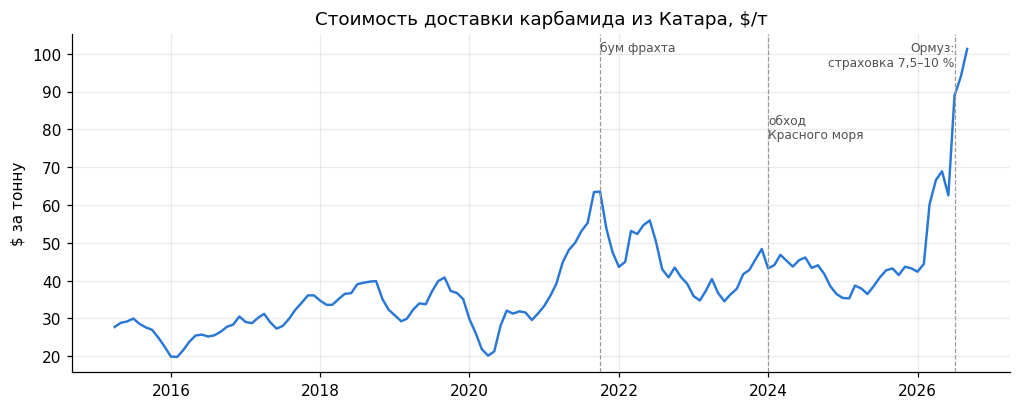

,месяцев,среднее,мин,макс,"аренда, %","топливо, %","сборы, %","страховка, %"
период,,,,,,,,
2015–2019,57,31.1,19.8,40.8,44.0,40.0,15.0,1.0
2020–2021,24,38.5,20.2,63.5,55.0,32.0,12.0,1.0
2022–2023,24,43.1,34.5,55.9,42.0,46.0,11.0,1.0
2024–2025,24,41.5,35.3,46.8,49.0,44.0,7.0,1.0
2026,9,69.9,42.4,101.3,40.0,33.0,4.0,23.0


In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df["tc"], color=C1, lw=1.6)
for x, t, yf in [("2021-10-01", "бум фрахта", 0.98), ("2024-01-01", "обход\nКрасного моря", 0.80), ("2026-07-01", "Ормуз:\nстраховка 7,5–10 %", 0.98)]:
    ax.axvline(pd.Timestamp(x), color="#9b9a95", lw=0.8, ls="--")
    ax.text(pd.Timestamp(x), ax.get_ylim()[1] * yf, t, ha="right" if x.startswith("2026") else "left",
            va="top", fontsize=8, color="#52514e")
ax.set_ylabel("$ за тонну"); ax.set_title("Стоимость доставки карбамида из Катара, $/т")
plt.show()

periods = {"2015–2019": ("2015-04", "2019-12"), "2020–2021": ("2020-01", "2021-12"), "2022–2023": ("2022-01", "2023-12"),
           "2024–2025": ("2024-01", "2025-12"), "2026": ("2026-01", "2026-09")}
rows = []
for name, (a, b) in periods.items():
    x = df.loc[a:b]
    share = (x[["hire", "fuel", "fees", "war"]].mean() / x["tc"].mean() * 100).round(0)
    rows.append({"период": name, "месяцев": len(x), "среднее": x["tc"].mean(), "мин": x["tc"].min(), "макс": x["tc"].max(),
                 "аренда, %": share["hire"], "топливо, %": share["fuel"], "сборы, %": share["fees"], "страховка, %": share["war"]})
pd.DataFrame(rows).set_index("период").round(1)

**Вывод.**
- 2015–2019: спокойно, в среднем $31/т, аренда и топливо примерно поровну (44 % и 40 %).
- 2020–2021: бум фрахта, пик $63/т, доля аренды вырастает до 55 %.
- 2022–2023: после скачка цен на нефть главной составляющей становится топливо (46 %).
- 2024–2025: плато около $41,5/т, обход Красного моря удорожает рейс, но сборы за Суэц падают, и итог почти не меняется.
- 2026: среднее $70/т, максимум $101/т. Военная страховка даёт 23 % стоимости, то есть вся разница с прошлыми годами — это сценарий Ормуза.

**Что это даёт:** до 2026 года доставка меняется в узком коридоре $20–63/т. В 2026 году ряд выходит из него за счёт страховки, а таких наблюдений всего 9.

## 3. Тесты стационарности: ADF и KPSS

**Зачем:** выбрать, в каком виде подавать доставку в модель — уровнем или изменением.

**Как читать:** ADF: p < 0,05 — ряд стационарен (возвращается к среднему). KPSS читается наоборот: p ≥ 0,05 — стационарен. Если тесты согласны, вывод надёжный. Такая же проверка сделана для надбавки в EDA Лизы.

In [4]:
rows = []
for col in ["tc", "d_tc", "r_tc", "markup"]:
    x = df[col].dropna()
    adf_t, adf_p, *_ = adfuller(x, autolag="AIC")
    _, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    rows.append({"ряд": col, "ADF p": round(adf_p, 3), "KPSS p": round(kpss_p, 3)})

x = df.loc[df.index < "2026-01-01", "tc"]               # устойчивость: без аномального 2026 года
rows.append({"ряд": "tc до 2026", "ADF p": round(adfuller(x, autolag="AIC")[1], 3), "KPSS p": None})
pd.DataFrame(rows)

,ряд,ADF p,KPSS p
0,tc,0.968,0.01
1,d_tc,0.001,0.10
2,r_tc,0.000,0.10
3,markup,0.010,0.10
4,tc до 2026,0.276,NaN


**Вывод.**

| Ряд | ADF p | KPSS p | Вывод |
|---|---|---|---|
| `tc` (уровень) | 0,968 | 0,01 | оба теста: **нестационарен** |
| `d_tc`, `r_tc` (изменение) | ≤ 0,001 | ≥ 0,10 | оба теста: **стационарны** |
| `tc` до 2026 | 0,276 | — | без 2026 года всё равно нестационарен |

**Что это даёт:** уровень доставки блуждает, как и цена карбамида, а надбавка стационарна (см. EDA цен). Поэтому в модель надбавки доставку нужно подавать **изменением** (`d_tc` или `r_tc`), а не уровнем: уровень не имеет общего среднего с надбавкой, и связь на уровнях была бы ложной.

## 4. С каким отставанием доставка связана с надбавкой

**Зачем:** проверить главную гипотезу — дорогая доставка снижает надбавку, и через какое время.

**Как читать:** столбик k — корреляция изменения надбавки в месяце t с изменением доставки в месяце t − k. Пунктир — граница случайности (≈ ±0,17): столбики внутри неё неотличимы от шума. Ожидаем отрицательные значения: доставка дорожает → надбавка падает.

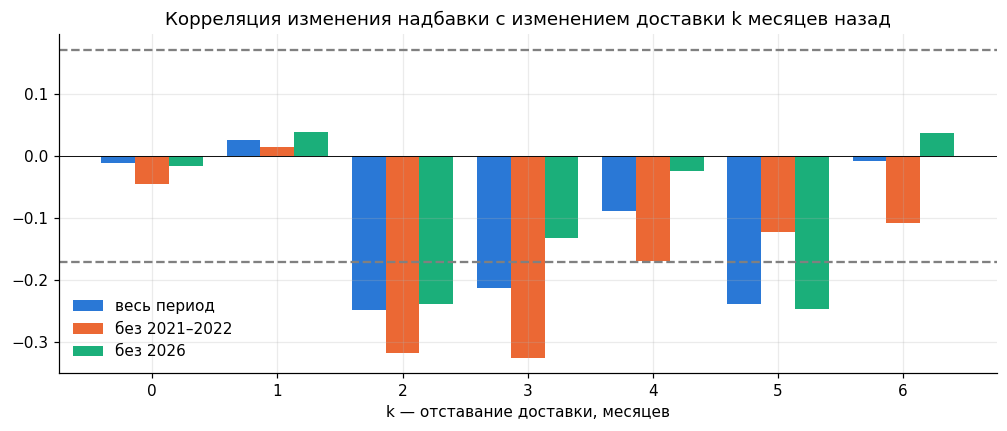

граница случайности ±0.171


,весь период,без 2021–2022,без 2026
0,-0.01,-0.05,-0.02
1,0.03,0.01,0.04
2,-0.25,-0.32,-0.24
3,-0.21,-0.33,-0.13
4,-0.09,-0.17,-0.03
5,-0.24,-0.12,-0.25
6,-0.01,-0.11,0.04


In [5]:
lags = range(0, 7)
band = 2 / np.sqrt(df["d_markup"].notna().sum())

def ccf(sub, x="d_tc", y="d_markup"):
    return pd.Series([sub[y].corr(sub[x].shift(k)) for k in lags], index=list(lags))

res = pd.DataFrame({"весь период": ccf(df),
                    "без 2021–2022": ccf(df[(df.index < "2021-01-01") | (df.index > "2022-12-01")]),
                    "без 2026": ccf(df[df.index < "2026-01-01"])})

fig, ax = plt.subplots(figsize=(11, 4))
w = 0.27
for i, (name, col) in enumerate(zip(res.columns, [C1, C2, C3])):
    ax.bar(res.index + (i - 1) * w, res[name], w, color=col, label=name)
ax.axhline(band, color="grey", ls="--"); ax.axhline(-band, color="grey", ls="--"); ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("k — отставание доставки, месяцев"); ax.set_title("Корреляция изменения надбавки с изменением доставки k месяцев назад")
ax.legend(frameon=False)
plt.show()
print(f"граница случайности ±{band:.3f}")
res.round(2)

**Вывод.** Связь есть, но слабая и с задержкой:
- Лаги 0 и 1: около нуля — сразу после удорожания доставки надбавка не реагирует.
- Лаги 2 и 3: −0,25 и −0,21 — выходят за границу случайности (±0,17), знак как в теории.
- Лаг 5: −0,24 — тоже за границей. Лаг 4 и 6 — шум.
- Если убрать кризис 2021–2022, связь **усиливается** (−0,32 и −0,33 на лагах 2–3): её создаёт не один аномальный период. Без 2026 года остаётся −0,24 на лаге 2, на лаге 3 падает до −0,13.

**Что это даёт:** доставка опережает надбавку на 2–3 месяца, по знаку это согласуется с формулой FOB = CIF − фрахт. Но корреляция −0,25 означает, что объясняется около 6 % изменений надбавки (r² = 0,06): сигнал слабый.

## 5. Тест Грейнджера: доставка → надбавка и обратно

**Зачем:** проверить, что прошлое доставки помогает предсказать надбавку сверх прошлого самой надбавки — и что связь идёт в нужную сторону, а не наоборот.

**Как читать:** нулевая гипотеза — прошлое первого ряда не помогает предсказать второй. p < 0,05 — гипотеза отвергается, связь есть. Смотрим оба направления.

In [6]:
def granger_p(x, y, maxlag=6):
    d = df[[y, x]].dropna()                              # первый столбец — предсказываемый, второй — «причина»
    r = grangercausalitytests(d, maxlag=maxlag, verbose=False)
    return [round(r[k][0]["ssr_ftest"][1], 3) for k in range(1, maxlag + 1)]

pd.DataFrame({"доставка → надбавка": granger_p("d_tc", "d_markup"),
              "надбавка → доставка": granger_p("d_markup", "d_tc"),
              "аренда → надбавка": granger_p("d_hire", "d_markup")},
             index=range(1, 7)).rename_axis("лаг, мес.")

,доставка → надбавка,надбавка → доставка,аренда → надбавка
"лаг, мес.",,,
1,0.768,0.652,0.925
2,0.007,0.791,0.089
3,0.009,0.906,0.143
4,0.010,0.785,0.312
5,0.000,0.679,0.143
6,0.000,0.545,0.081


**Вывод.** Доставка → надбавка: p = 0,77 на лаге 1, затем 0,007–0,010 на лагах 2–4 и 0,000 на лагах 5–6 — связь значима, начиная со второго месяца. Надбавка → доставка: p = 0,55–0,91 на всех лагах, обратной связи нет. Направление правильное: доставка влияет на надбавку, а не наоборот (что логично, фрахт не зависит от цены удобрения в короткой перспективе).

**Осторожно:** это статистическая связь, а не доказательство причины. Тест не учитывает, что и доставка, и надбавка зависят от общих факторов (в первую очередь от цены нефти). Об этом — следующий раздел.

## 6. Что именно в доставке несёт сигнал: аренда или топливо

**Зачем:** `tc` сложена из аренды (BDI), топлива (Brent), сборов и страховки. Нужно понять, какая часть связана с надбавкой, потому что Brent у команды уже есть в данных.

**Как читать:** те же корреляции с надбавкой, но отдельно для изменения аренды, топлива и «всего, кроме топлива».

In [7]:
parts = pd.DataFrame({"аренда": ccf(df, "d_hire"), "топливо": ccf(df, "d_fuel"), "всё, кроме топлива": ccf(df, "d_nofuel")})
print(f"граница случайности ±{band:.3f}")
display(parts.round(2))

print("Тест Грейнджера, аренда → надбавка, p по лагам 1–6:", granger_p("d_hire", "d_markup"))
print(f"Корреляция d_tc с изменением Brent: {df['d_tc'].corr(df['brent'].diff()):.2f}")

граница случайности ±0.171


,аренда,топливо,"всё, кроме топлива"
0,-0.02,0.12,-0.07
1,0.01,0.09,-0.01
2,-0.15,-0.24,-0.17
3,-0.16,-0.08,-0.22
4,0.00,-0.14,-0.02
5,-0.11,-0.28,-0.13
6,0.09,-0.12,0.06


Тест Грейнджера, аренда → надбавка, p по лагам 1–6: [0.925, 0.089, 0.143, 0.312, 0.143, 0.081]
Корреляция d_tc с изменением Brent: 0.51


**Вывод.**
- Топливо: −0,24 на лаге 2 и −0,28 на лаге 5 — основная часть сигнала.
- Аренда (BDI): −0,15 / −0,16 на лагах 2–3 — внутри границы случайности (±0,17). Тест Грейнджера для аренды: p = 0,08–0,93, **не значим** ни на одном лаге.
- Изменение доставки на 0,51 повторяет изменение Brent: большая часть движения `tc` — это нефть.

**Что это даёт:** связь доставки с надбавкой — в основном связь надбавки с нефтью, а не с фрахтом судов. Чистый «судовой» сигнал (аренда) слабее и статистически не доказан.

## 7. Добавляет ли доставка что-то к газу и нефти

**Зачем:** главная проверка полезности признака. Если в модель уже входят газ и Brent, нужна ли ей ещё доставка?

**Как читать:** две линейные регрессии изменения надбавки. Базовая — на газ (лаги 0–2) и Brent (лаги 0–3). Расширенная — плюс изменение доставки на лагах 2 и 3 (там была связь). Сравниваем скорректированный R² (он штрафует за лишние признаки) и F-тест: p < 0,05 — добавка статистически полезна.

In [8]:
X0 = pd.concat({f"gas_{k}": df["d_gas"].shift(k) for k in (0, 1, 2)} |
               {f"brent_{k}": df["d_brent"].shift(k) for k in (0, 1, 2, 3)}, axis=1)
X1 = pd.concat([X0, pd.concat({f"tc_{k}": df["d_tc"].shift(k) for k in (2, 3)}, axis=1)], axis=1)
D = pd.concat([df["d_markup"].rename("y"), X1], axis=1).dropna()

m0 = sm.OLS(D["y"], sm.add_constant(D[X0.columns])).fit()
m1 = sm.OLS(D["y"], sm.add_constant(D[X1.columns])).fit()
print(f"наблюдений: {len(D)}")
print(f"без доставки:  R² = {m0.rsquared:.3f}, скорректированный R² = {m0.rsquared_adj:.3f}")
print(f"с доставкой:   R² = {m1.rsquared:.3f}, скорректированный R² = {m1.rsquared_adj:.3f}")
print(f"F-тест добавки (доставка, лаги 2 и 3): p = {m1.compare_f_test(m0)[1]:.3f}")

наблюдений: 134
без доставки:  R² = 0.826, скорректированный R² = 0.817
с доставкой:   R² = 0.830, скорректированный R² = 0.817
F-тест добавки (доставка, лаги 2 и 3): p = 0.315


**Вывод.** Скорректированный R² не меняется (0,817 → 0,817), F-тест p = 0,31: **доставка в линейной модели ничего не добавляет к газу и Brent.**

**Оговорка:** высокий R² базовой модели (0,83) во многом механический — надбавка по определению содержит цену газа, поэтому изменение газа в том же месяце объясняет её почти «по построению». Для нашего вопроса важно другое: поверх этой базы доставка не улучшает объяснение. Тест линейный и на 134 наблюдениях: слабую или нелинейную связь он мог бы не заметить.

## 8. Сверка сценариев с реальным трафиком судов (PortWatch)

**Зачем:** в ряд `tc` мы заложили сценарии: с января 2024 суда обходят Красное море, с марта 2026 включается военная страховка Ормуза (8,5 $/т), с июля она растёт до 37,2 $/т. Данные PortWatch — это число судов в день, прошедших пролив. Проверяем, подтверждает ли реальный трафик наши сценарии, и есть ли у трафика связь с надбавкой.

**Как читать:** «норма» — средний трафик 2023–2025 годов. Если сценарий верный, трафик должен резко упасть в тот месяц, где мы включили страховку. Данные PortWatch есть только с января 2019 года.

In [9]:
pw = pd.read_csv("../data/raw/portwatch_transport_features_monthly.csv", parse_dates=["date"]).set_index("date")
HZ, HZD, BAB = "hormuz_n_total_mean", "hormuz_n_dry_bulk_mean", "bab_el_mandeb_n_dry_bulk_mean"   # судов в день: Ормуз всего, Ормуз сухогрузы, Баб-эль-Мандеб сухогрузы
d8 = df[["war", "tc", "markup", "d_markup"]].join(pw)
print(f"месяцев с данными PortWatch: {int(pw[HZ].notna().sum())} из {len(pw)}, первый месяц {pw[HZ].first_valid_index():%Y-%m}")

norm = d8.loc["2023-01":"2025-12", [HZ, HZD]].mean()
print(f"норма 2023–2025: {norm[HZ]:.1f} судов в день через Ормуз, из них сухогрузов {norm[HZD]:.1f}")

rows = []
for name, (a, z) in {"окт. 2025 – фев. 2026": ("2025-10", "2026-02"), "март – июнь 2026": ("2026-03", "2026-06"),
                     "июль – сентябрь 2026": ("2026-07", "2026-09")}.items():
    x = d8.loc[a:z]
    rows.append({"период": name, "судов в день": x[HZ].mean(), "сухогрузов в день": x[HZD].mean(),
                 "сухогрузов, % нормы": x[HZD].mean() / norm[HZD] * 100, "страховка в сценарии, $/т": x["war"].mean()})
pd.DataFrame(rows).set_index("период").round(1)

месяцев с данными PortWatch: 93 из 138, первый месяц 2019-01
норма 2023–2025: 89.6 судов в день через Ормуз, из них сухогрузов 14.1


,судов в день,сухогрузов в день,"сухогрузов, % нормы","страховка в сценарии, $/т"
период,,,,
окт. 2025 – фев. 2026,69.8,11.7,82.9,0.3
март – июнь 2026,6.8,2.1,15.2,8.5
июль – сентябрь 2026,6.2,1.9,13.4,37.2


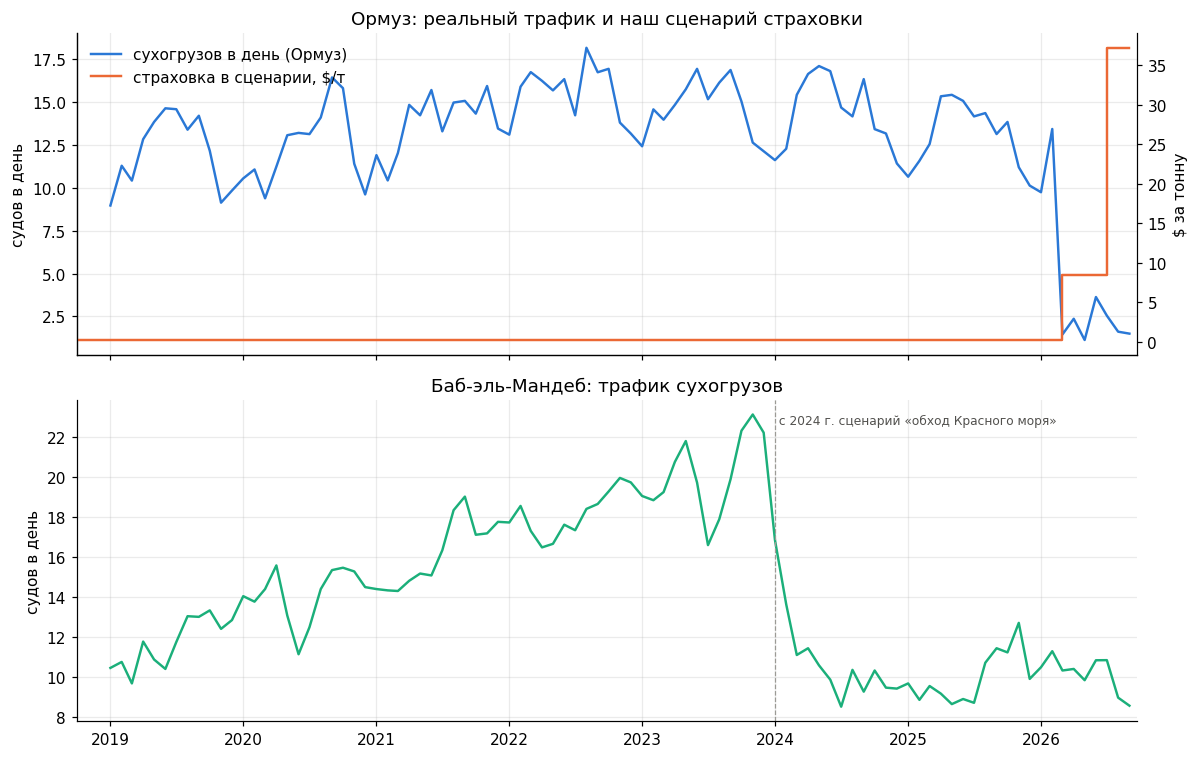

,сухогрузов в день
"2019–2023, среднее",16.0
декабрь 2023,22.2
январь 2024,16.8
февраль 2024,13.6
март 2024,11.1
"2024–2025, среднее",10.4


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax = axes[0]
ax.plot(d8.index, d8[HZD], color=C1, lw=1.6, label="сухогрузов в день (Ормуз)")
ax.set_ylabel("судов в день")
ax2 = ax.twinx(); ax2.grid(False)
ax2.step(d8.index, d8["war"], where="post", color=C2, lw=1.6, label="страховка в сценарии, $/т")
ax2.set_ylabel("$ за тонну"); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left"); ax.set_title("Ормуз: реальный трафик и наш сценарий страховки")

ax = axes[1]
ax.plot(d8.index, d8[BAB], color=C3, lw=1.6)
ax.axvline(pd.Timestamp("2024-01-01"), color="#9b9a95", lw=0.8, ls="--")
ax.text(pd.Timestamp("2024-01-01"), ax.get_ylim()[1] * 0.97, " с 2024 г. сценарий «обход Красного моря»", va="top", fontsize=8, color="#52514e")
ax.set_ylabel("судов в день"); ax.set_title("Баб-эль-Мандеб: трафик сухогрузов")
ax.set_xlim(pd.Timestamp("2018-10-01"), d8.index.max() + pd.Timedelta(days=20))   # данные PortWatch начинаются с 2019 года
plt.tight_layout(); plt.show()

bab = pd.Series({"2019–2023, среднее": d8.loc["2019":"2023", BAB].mean(), "декабрь 2023": d8.loc[pd.Timestamp("2023-12-01"), BAB],
                 "январь 2024": d8.loc[pd.Timestamp("2024-01-01"), BAB], "февраль 2024": d8.loc[pd.Timestamp("2024-02-01"), BAB], "март 2024": d8.loc[pd.Timestamp("2024-03-01"), BAB],
                 "2024–2025, среднее": d8.loc["2024":"2025", BAB].mean()}, name="сухогрузов в день")
bab.round(1).to_frame()

In [11]:
d8["d_log_hz"] = np.log(d8[HZD].clip(lower=0.5)).diff()   # изменение трафика сухогрузов в % за месяц (нули защищены от логарифма)
s8 = d8.dropna(subset=["d_log_hz", "d_markup"])
band8 = 2 / np.sqrt(len(s8))
corr8 = pd.Series([s8["d_markup"].corr(s8["d_log_hz"].shift(k)) for k in range(5)], index=range(5), name="корреляция")
print(f"наблюдений: {len(s8)}, граница случайности ±{band8:.3f}")
print("Тест Грейнджера, трафик → надбавка, p по лагам 1–4:",
      [round(r[0]["ssr_ftest"][1], 3) for r in grangercausalitytests(s8[["d_markup", "d_log_hz"]], maxlag=4, verbose=False).values()])
corr8.round(2).to_frame().rename_axis("лаг, мес.")

наблюдений: 92, граница случайности ±0.209
Тест Грейнджера, трафик → надбавка, p по лагам 1–4: [0.484, 0.661, 0.508, 0.72]


,корреляция
"лаг, мес.",
0,-0.08
1,-0.08
2,0.07
3,0.12
4,-0.03


**Вывод.**
- **Март 2026 подтверждён.** В норме через Ормуз проходит ~90 судов в день (14 сухогрузов). С марта — около 7 судов в день, сухогрузов 2 (15 % нормы). Страховку в сценарии мы включили ровно в этом месяце.
- **Июльский скачок не подтверждён.** Трафик в марте–июне и в июле–сентябре почти одинаковый (2,1 и 1,9 сухогруза в день, 15 % и 13 % нормы), а страховка в сценарии выросла в 4,4 раза (8,5 → 37,2 $/т). Этот уровень держится на данных о страховых ставках, не на трафике; в PortWatch второго обвала нет.
- **Красное море подтверждено, но переход был постепенным.** Сухогрузов в день: 22,2 в декабре 2023, затем 16,8 → 13,6 → 11,1 в январе–марте 2024; в среднем 16,0 за 2019–2023 и 10,4 за 2024–2025. В сценарии мы переключаемся на обход одним шагом в январе 2024.
- **Связи трафика с надбавкой нет.** Корреляции −0,08 / −0,08 / 0,07 / 0,12 / −0,03 на лагах 0–4 (граница ±0,21), тест Грейнджера p = 0,48–0,72. Надбавка в 2026 году сначала выросла (до $456/т в апреле), потом ушла в минус (−$253/т в сентябре), а трафик всё это время был на одном низком уровне.

**Что это даёт:** данные PortWatch подтверждают сами события, но не помогают прогнозировать надбавку: «закрытие» длится всего 7 месяцев, и за это время надбавка успела сделать и взлёт, и падение при неизменном трафике. Для модели трафик можно использовать как индикатор режима «пролив закрыт» (0/1), но не как количественный признак.

## Итог: что мы получили для модели

1. **`tc` нестационарна, её изменения стационарны.** В модель надбавки подавать `d_tc` / `r_tc`, не уровень.
2. **Связь с надбавкой есть, но слабая и с задержкой 2–3 месяца.** Корреляция ≈ −0,25, Грейнджер доставка → надбавка значим на лагах 2–6, обратно связи нет, знак соответствует формуле FOB = CIF − фрахт. Связь устойчива к исключению кризиса 2021–2022.
3. **Сигнал в основном нефтяной.** Топливная часть даёт связь, чистая аренда (BDI) — нет (Грейнджер p ≥ 0,08). Brent в модели и так будет.
4. **Поверх газа и Brent доставка ничего не добавляет** (скорректированный R² 0,817 → 0,817, p = 0,31). Не стоит ждать от `transport_cost_per_t` заметного прироста качества.
5. **Часть ряда — наши допущения.** Военная страховка — три сценарных уровня, 2026 год даёт всего 9 наблюдений. Данные PortWatch подтверждают март 2026 (трафик через Ормуз упал до 15 % нормы) и переход на обход Красного моря в 2024 году, но не подтверждают июльский рост страховки: трафик в июле не менялся. Связи трафика с надбавкой нет (p = 0,48–0,72).

**Что делать на чекпоинте 3:**
- Включить `d_tc` (лаги 2–3) и `d_hire` (лаги 2–3) как кандидатов и проверить на отложенной выборке, не рассчитывая на большой эффект.
- Сравнить модели с признаком и без: если разницы нет, оставить как объяснение механизма, а не как фактор точности.
- Данные PortWatch получены (Александр Нечепоренко, с января 2019 года). Использовать трафик Ормуза как индикатор режима «пролив закрыт» (0/1) вместо ступенчатой страховки; уровень 37,2 $/т с июля 2026 пересмотреть, так как трафик его не подтверждает.
- Сделать переход на обход Красного моря постепенным (январь – март 2024), а не одним шагом.
- Учесть, что с марта 2026 поток из Катара почти остановлен: стоимость рейса за эти месяцы описывает доставку, которой почти не было.
- Уточнить аренду полным рядом индекса Supramax (BSI): сейчас ставка откалибрована по 3 точкам.